# From an SDSS identifier to an emission-line measurement

This notebook follows one spectrum the whole way: a plate, an MJD and a fibre
number become a URL, the URL becomes 600 KB of FITS, the FITS becomes a
measurement, and the measurement comes with a record of the bytes it came from.

The rule the whole workflow is built on:

> **Adapt the input to the validated pipeline. Never adapt the fitter to make the
> input work.**

`gspec` was validated on twenty spectra and its numbers are what the repository
publishes. Nothing here touches the fitter. The converter produces exactly the
schema `gspec.read_case` already expects, so the measurement path is the same one
every other number in this project went through.

**What you need.** `numpy`, `scipy`, `astropy`, `matplotlib`, and `gspec`
installed (`pip install -e .` from the repository root). Network access for the
download step; once the file is on disk the notebook runs offline.

## 1. What is in an SDSS spectrum file

An optical spectrum is flux density as a function of wavelength. The SDSS
spectrograph disperses light onto 640 fibres at once, each recorded on a CCD, and
the survey's spectroscopic pipeline reduces every fibre to a calibrated one-
dimensional spectrum. The file you are about to download is one of those: a single
object, already sky-subtracted and flux-calibrated, from the SDSS-I/II Legacy
survey reduced with `run2d=26`.

Three things about it matter here.

*The wavelength grid is logarithmic.* The pixels are equally spaced in
$\log_{10}\lambda$, so

$$\log_{10}\lambda_i = \mathrm{COEFF0} + i\cdot\mathrm{COEFF1}
\qquad\Longleftrightarrow\qquad \Delta\lambda = \ln(10)\,\mathrm{COEFF1}\,\lambda,$$

with `COEFF1 = 1e-4`. A pixel therefore covers 0.92 Å at 4000 Å and 2.0 Å at
8800 Å. The dispersion is not constant in wavelength, and any code that assumes it
is will bias line widths.

*Flux is a density, not an integral.* `flux` is in
$10^{-17}\,\mathrm{erg\,s^{-1}\,cm^{-2}\,\AA^{-1}}$. An emission-line flux is
the integral of that over the line profile; it is not a column of the table.

*The noise is stored as inverse variance.* `ivar` is $1/\sigma^2$ in the same
units squared. `ivar = 0` means *no information*, which is not the same as *zero
uncertainty* — a distinction the masking below depends on.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits

# find the repository root from wherever this notebook is run
ROOT = Path.cwd()
while not (ROOT / "pyproject.toml").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "tools"))

import download_sdss as D
import fits_to_case

import gspec

print("repository:", ROOT)
print("gspec", gspec.__version__, "| numpy", np.__version__, "| astropy", fits.__name__ and __import__("astropy").__version__)

repository: /tmp/nbfinal
gspec 0.3.0 | numpy 1.26.4 | astropy 7.0.0


## 2. Identifying a spectrum in the archive

The SDSS archive addresses a spectrum by three integers: **plate** (which
plug-plate was drilled), **MJD** (which night it was observed) and **fibre** (which
hole on that plate). Together they are unique.

The Data Release 18 Science Archive Server path for the Legacy reduction is

```
https://data.sdss.org/sas/dr18/prior-surveys/sdss2-dr8-sdss/spectro/redux/26/
        spectra/{plate:04d}/spec-{plate:04d}-{mjd:05d}-{fiber:04d}.fits
```

Plate and fibre are zero-padded to four digits in **both** the directory and the
file name; MJD to five. (DATA.md quoted the directory as `{plate}` unpadded. That
path returns 404 — the padded one returns 200 — so the padding is not cosmetic.)

Identifiers are validated as integers inside documented ranges *before* any URL
string exists, so a stray string can never be interpolated into a request.

In [2]:
PLATE, MJD, FIBER = 294, 51986, 36

print(D.filename_for(PLATE, MJD, FIBER))
print(D.url_for(PLATE, MJD, FIBER))

for bad in [("294", "51986", "36abc"), ("0", "51986", "36")]:
    try:
        D.validate_triple(*bad)
    except D.IdentifierError as exc:
        print("rejected:", exc)

spec-0294-51986-0036.fits
https://data.sdss.org/sas/dr18/prior-surveys/sdss2-dr8-sdss/spectro/redux/26/spectra/0294/spec-0294-51986-0036.fits
rejected: fiber must be a plain integer; got '36abc'
rejected: plate=0 is outside the documented range 1-9999


## 3. Downloading, with checks that can fail

A download is only useful if a bad one is obvious. The tool runs the file through
these gates, in this order:

| gate | catches |
|---|---|
| HTTP status | an object that does not exist (404, not retried) or a broken server (5xx, retried with backoff) |
| `Content-Length` vs bytes written | a truncated transfer |
| SHA-256 against a recorded value | silent corruption, or the wrong object |
| `fits.open()` | an HTML error page saved with a `.fits` name |
| the instrument contract (next section) | schema drift between reductions |

Two design choices matter when it goes wrong. The bytes land in a `.part` file and
are renamed only after the checks pass, so a file with the final name is always a
complete file. And an existing file is never replaced without `--force`: the tool
will not silently overwrite yesterday's download with today's.

The project records the SHA-256 of the archive files its cases were built from, so
we can check this download against that record rather than trusting the server.

The same two steps from a shell, without a notebook:

```bash
python tools/download_sdss.py --plate 294 --mjd 51986 --fiber 36 --out data/raw
gspec measure --cases data/raw/cases --out data/raw/measurements.csv
```

`tools/download_sdss.py` is the programmatic surface; the cell below calls the same
function it calls (`download_sdss.fetch_one`), with the same defaults, so the two
routes cannot drift apart.


In [3]:
raw_dir = ROOT / "data" / "raw"
name = D.filename_for(PLATE, MJD, FIBER)

expected = None
for line in (ROOT / "data" / "provenance" / "sha256_data.txt").read_text().splitlines():
    if line.strip().endswith(name):
        expected = line.split()[0]
print("recorded sha256:", expected)

result = D.fetch_one(PLATE, MJD, FIBER, raw_dir, expected_sha256=expected)
print("status:", result.status, "| bytes:", result.bytes, "| sha256:", result.sha256[:24], "...")

recorded sha256: 12e069c2cceb53459b49204f3f508aef3acdd704fd14a136c0b6449e8a118554
status: fetched | bytes: 604800 | sha256: 12e069c2cceb53459b49204f ...


In [4]:
print(json.dumps({k: result.__dict__[k] for k in
                  ("case_id", "url", "status", "bytes", "sha256", "retrieved_utc", "http")},
                 indent=2))

{
  "case_id": "SDSS-0294-51986-0036",
  "url": "https://data.sdss.org/sas/dr18/prior-surveys/sdss2-dr8-sdss/spectro/redux/26/spectra/0294/spec-0294-51986-0036.fits",
  "status": "fetched",
  "bytes": 604800,
  "sha256": "12e069c2cceb53459b49204f3f508aef3acdd704fd14a136c0b6449e8a118554",
  "retrieved_utc": "2026-11-17T01:04:21Z",
  "http": {
    "status": 200,
    "etag": "\"4fa1992e-93a80\"",
    "last_modified": "Wed, 02 May 2012 20:29:34 GMT",
    "content_length": 604800,
    "accept_ranges": "bytes",
    "bytes_written": 604800,
    "resumed_from": 0
  }
}


Note what the record separates: `http` holds what the **server said** (status,
ETag, last-modified, content-length), the fields beside it hold what **we**
measured (bytes written, SHA-256), and the identifiers came from us. Nothing in
provenance is a guess.

## 4. Inside the file

The archive file has more in it than the spectrum. It carries the survey
pipeline's own fit (`SPZLINE`: line fluxes and redshifts) and the catalogue entry
(`SPECOBJ`: object class, redshift). Those are the answers to the question this
project asks, and they are never carried downstream.

In [5]:
with fits.open(result.path) as hdul:
    hdul.info()
    prim = hdul[0].header
    coadd = hdul["COADD"].data
    print()
    print("dispersion:", f"COEFF0={prim['COEFF0']}  COEFF1={prim['COEFF1']}  DC-FLAG={prim['DC-FLAG']}")
    print("units     :", prim["BUNIT"], "| vacuum:", prim["VACUUM"])
    print("columns   :", [c.name for c in hdul["COADD"].columns])

    lam = 10 ** coadd["loglam"].astype(float)
    ivar = coadd["ivar"].astype(float)
    print()
    print(f"pixels        : {len(coadd)}")
    print(f"wavelength    : {lam[0]:.1f} - {lam[-1]:.1f} A")
    print(f"[log10] step  : {np.diff(coadd['loglam']).mean():.6f}")
    print(f"ivar > 0      : {(ivar > 0).mean():.1%} of pixels")
    print(f"pixels flagged: {(coadd['and_mask'] != 0).sum()}")

Filename: /tmp/nbfinal/data/raw/spec-0294-51986-0036.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU     139   ()      
  1  COADD         1 BinTableHDU     26   3828R x 8C   [E, E, E, J, J, E, E, E]   
  2  SPECOBJ       1 BinTableHDU    262   1R x 126C   [6A, 4A, 16A, 23A, 16A, 8A, E, E, E, J, E, E, J, B, B, B, B, B, B, J, 22A, 19A, 19A, 22A, 19A, I, 3A, 3A, 1A, J, D, D, D, E, E, 19A, 8A, J, J, J, J, K, K, J, J, J, J, J, J, K, K, K, K, I, J, J, J, J, 5J, D, D, 6A, 21A, E, E, E, J, E, 24A, 10J, J, 10E, E, E, E, E, E, E, J, E, E, E, J, E, 5E, E, 10E, 10E, 10E, 5E, 5E, 5E, 5E, 5E, J, J, E, E, E, E, E, E, 25A, 21A, 10A, E, E, E, E, E, E, E, E, J, E, E, J, 1A, 1A, E, E, J, J, 1A, 5E, 5E]   
  3  SPZLINE       1 BinTableHDU     48   29R x 19C   [J, J, J, 13A, D, E, E, E, E, E, E, E, E, E, E, J, J, E, E]   
  4  B1-00009081-00009085-00009086    1 BinTableHDU    146   2044R x 7C   [E, E, E, J, E, E, E]   
  5  B1-00009082-00009085-00009086  

## 5. The instrumental resolution: is `wdisp` in pixels or in Ångström?

This looks like a detail. It is not: the pipeline convolves its model with the
instrumental line-spread function, so a width interpreted in the wrong unit
misprices every line width, and through the widths it changes the fitted fluxes.

The archive file carries `wdisp` with no `TUNIT` on the column, so the unit has to
be settled from the data. The argument is a physical one. For a spectrograph of
roughly constant resolving power $R = \lambda/\Delta\lambda_{\rm FWHM}$, the
resolution width *in Ångström* grows with wavelength, while the width *in pixels*
shrinks, because a pixel covers more Ångström at the red end:

$$\sigma_\lambda \propto \lambda
\quad\Rightarrow\quad
\sigma_{\rm pixel} = \frac{\sigma_\lambda}{\Delta\lambda} \propto \frac{\lambda}{\lambda} = \text{const}.$$

So: if `wdisp` rises with $\lambda$, it is in Ångström; if it falls roughly like
$1/\Delta\lambda$, it is in pixels. Let us look.

In [6]:
lam = 10 ** coadd["loglam"].astype(float)
dlam = np.gradient(lam)
w = coadd["wdisp"].astype(float)
valid = ivar > 0

print(f"{'lambda (A)':>11} {'wdisp':>8} {'dlam (A)':>9} {'wdisp*dlam (A)':>15} {'R':>6}")
for q in range(10):
    seg = np.where(valid)[0][q * valid.sum() // 10:(q + 1) * valid.sum() // 10]
    s_l = lam[seg].mean(); s_w = np.median(w[seg]); s_d = dlam[seg].mean()
    print(f"{s_l:11.1f} {s_w:8.4f} {s_d:9.4f} {s_w * s_d:15.3f} {s_l / (2.355 * s_w * s_d):6.0f}")

 lambda (A)    wdisp  dlam (A)  wdisp*dlam (A)      R
     3983.7   1.2577    0.9173           1.154   1466
     4350.5   1.1404    1.0017           1.142   1617
     4751.6   1.0279    1.0941           1.125   1794
     5189.7   0.9236    1.1950           1.104   1997
     5668.1   0.8420    1.3051           1.099   2190
     6190.0   0.9119    1.4253           1.300   2022
     6759.9   0.8508    1.5565           1.324   2168
     7383.1   0.7813    1.7000           1.328   2360
     8063.8   0.7286    1.8568           1.353   2531
     8807.3   0.6959    2.0279           1.411   2650


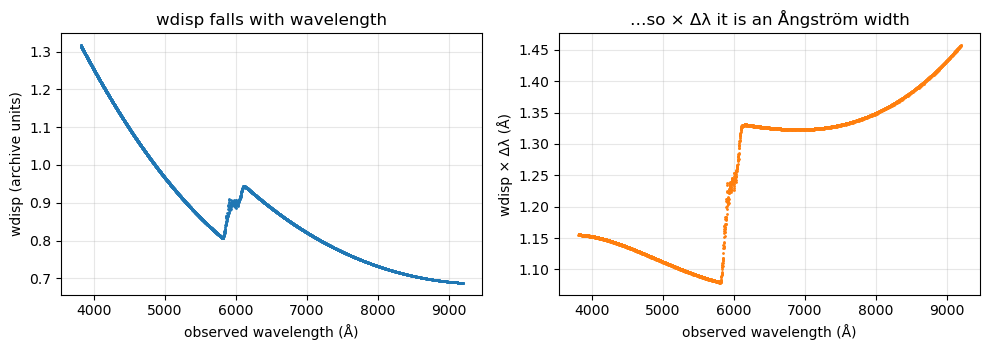

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
ax[0].plot(lam[valid], w[valid], ".", ms=2, color="C0")
ax[0].set_xlabel("observed wavelength (Å)"); ax[0].set_ylabel("wdisp (archive units)")
ax[0].set_title("wdisp falls with wavelength")

ax[1].plot(lam[valid], (w * dlam)[valid], ".", ms=2, color="C1")
ax[1].set_xlabel("observed wavelength (Å)"); ax[1].set_ylabel("wdisp × Δλ (Å)")
ax[1].set_title("…so × Δλ it is an Ångström width")
for a in ax:
    a.grid(alpha=.3)
plt.tight_layout(); plt.show()

`wdisp` falls from about 1.26 at 4000 Å to 0.73 at 8800 Å while the pixel width
grows from 0.92 Å to 2.03 Å. The product is a gently rising 1.1–1.4 Å, and
$R = \lambda/(2.355\,\sigma_\lambda)$ comes out near 1500 at 4000 Å and 2100 at
Hα — which is the published shape of the Legacy spectrograph's resolution curve.
Interpreted as Ångström instead, the same numbers would give $R \approx 3200$,
inconsistent with the instrument.

**Conclusion: `wdisp` is in pixels**, and multiplying by the local $\Delta\lambda$
is correct. The converter asserts this: a file whose `wdisp` grows with wavelength
is refused, because it would mean the opposite convention.

## 6. Converting to the case schema

A case file is a small FITS: a PRIMARY header carrying `CASEID`, `BUNIT`,
`VACUUM`, `PROVEN`, and one binary table of six columns — `flux`, `loglam`,
`ivar`, `and_mask`, `or_mask`, `wdisp` — in the archive's stored precision.

The conversion is a *copy*, not a transformation. There is no interpolation, no
resampling, no smoothing, no renormalisation: the pixels you downloaded are the
pixels that get fitted. What is dropped is the container — the `sky` and `model`
columns, and the `SPECOBJ` and `SPZLINE` extensions — and the provenance sidecar
records exactly what was dropped.

In [8]:
cases_dir = ROOT / "data" / "raw" / "cases"
case_path = cases_dir / (Path(result.path).stem + ".fits")
record = fits_to_case.convert(result.path, case_path, force=True)

print("case:", record["case_path"])
print("case sha256:", record["case"]["sha256"])
print("dropped columns:", record["conversion"]["columns_dropped"])
print("dropped extensions:", record["conversion"]["extensions_dropped"])
print("resampling:", record["conversion"]["resampling"], "| smoothing:", record["conversion"]["smoothing"])

with fits.open(case_path) as h:
    print()
    print("PRIMARY:", {k: h[0].header[k] for k in ("CASEID", "BUNIT", "VACUUM", "PROVEN", "NWAVE")})
    print("COADD  :", [(c.name, c.format, c.unit) for c in h[1].columns])

case: /tmp/nbfinal/data/raw/cases/spec-0294-51986-0036.fits
case sha256: 3f35ce89277a08d9280627042524cd2e486c426e7d960cb33e7b12952e2afc8e
dropped columns: ['sky', 'model']
dropped extensions: ['0:PRIMARY', '2:SPECOBJ', '3:SPZLINE', '4:B1-00009081-00009085-00009086', '5:B1-00009082-00009085-00009086', '6:B1-00009083-00009085-00009086', '7:R1-00009081-00009085-00009086', '8:R1-00009082-00009085-00009086', '9:R1-00009083-00009085-00009086']
resampling: none | smoothing: none

PRIMARY: {'CASEID': 'SDSS-0294-51986-0036', 'BUNIT': '1E-17 erg/cm^2/s/Ang', 'VACUUM': True, 'PROVEN': 'sdss-raw', 'NWAVE': 3828}
COADD  : [('flux', 'E', '1E-17 erg/cm^2/s/Ang'), ('loglam', 'E', 'log10(Angstrom)'), ('ivar', 'E', '(1e-17 erg/s/cm2/A)^-2'), ('and_mask', 'J', None), ('or_mask', 'J', None), ('wdisp', 'E', 'pixel')]


In [9]:
# the six columns survive the trip unchanged
raw_data = fits.open(result.path)["COADD"].data
case_data = fits.open(case_path)["COADD"].data if "COADD" in [e.name for e in fits.open(case_path)] else fits.open(case_path)[1].data
print("same length:", len(raw_data) == len(case_data))
for col in fits_to_case.CASE_COLUMNS:
    print(f"  {col:9s} identical: {bool((np.asarray(raw_data[col]) == np.asarray(case_data[col])).all())}")

same length: True
  flux      identical: True
  loglam    identical: True
  ivar      identical: True
  and_mask  identical: True
  or_mask   identical: True
  wdisp     identical: True


## 7. Measuring

`gspec.measure` fits one model to both line windows at once — Hα with [N II] and
[S II], Hβ with [O III] — sharing a single redshift, with a polynomial continuum
per window and a stellar-absorption term whose inclusion is decided by BIC. The
reported flux of a line is the **integral** of its Gaussian component,

$$F = \frac{A\,\sigma_{\rm obs}\sqrt{2\pi}}{\Delta\lambda_{\rm pixel}}\times\Delta\lambda_{\rm pixel}
= A\,\sigma_{\rm obs}\sqrt{2\pi},$$

evaluated on the pixel grid, with the instrumental width deconvolved from the
observed one. The uncertainty comes from the fit's covariance, propagated through
the same arithmetic.

In [10]:
case = gspec.read_case(case_path)
measured = gspec.measure(case)

print(f"case            {measured.case_id}")
print(f"redshift        z = {measured.redshift:.6f}   (+/- {measured.redshift_err:.6f})")
print(f"model selected  {measured.model_selected}")
print()
print(f"{'line':<11}{'rest (A)':>10}{'flux':>12}{'err':>9}  {'S/N':>6}  flag")
for line in measured.lines:
    row = measured.row(line)
    sn = row["flux"] / row["flux_err"] if row["flux_err"] else float("nan")
    print(f"{row['line']:<11}{gspec.constants.TARGET_LINES[line]:10.2f}"
          f"{row['flux']:12.3f}{row['flux_err']:9.3f}  {sn:6.1f}  {row['flag']}")

case            SDSS-0294-51986-0036
redshift        z = 0.081202   (+/- 0.000035)
model selected  with-abs, ndeg=3, no broad Ha

line         rest (A)        flux      err     S/N  flag
Halpha        6564.61       9.878    5.031     2.0  nondetection
Hbeta         4862.68      56.292  449.299     0.1  nondetection
OIII_5007     5008.24       1.628    2.561     0.6  nondetection
NII_6583      6585.27       8.851    1.798     4.9  ok


**This object is faint, and the output says so.** Three of the four lines come
back as `nondetection`: Hα at S/N 2, [O III] at 0.6, and Hβ with an uncertainty
eight times its own flux. Only [N II] is recovered with a signal worth quoting.

That is the pipeline working, not failing. The flux printed beside a nondetection
is a limit — the fit could not separate the line from the continuum — and reading
it as a measurement is the most common way to misuse this kind of output. A
tutorial that showed only clean detections would misrepresent what the method does
on a typical 3800–9200 Å Legacy spectrum.

## 8. Reading the numbers

**The redshift** is $z = \Delta\lambda/\lambda_{\rm rest}$, measured from the
*pattern* of line positions, not from any single line. It is not a distance:
converting to one needs a cosmological model and a peculiar-velocity correction,
neither of which is in scope here. The uncertainty quoted is statistical only.

**The fluxes** are integrated line fluxes in $10^{-17}\,{\rm erg\,s^{-1}\,cm^{-2}}$,
corrected for instrumental broadening but *not* for dust extinction or for the
aperture — they are what falls down the fibre, roughly 3 arcsec.

**The flags** are the pipeline's own verdict, and they are the part a new user
should read first. `ok` means the line was recovered with a plausible width and a
signal-to-noise above the detection floor. `nondetection` means the fit could not
distinguish the line from the continuum at that floor: the flux printed beside it
is a limit, not a measurement, and should be read as one. `unresolved_blend` means
a line was detected but its width sits on the model's bound, so its flux and its
neighbour's cannot be separated.

One caution that applies here specifically. The project's own validation found
that **Hβ is the least reliable of these four lines**. Across four fitting
configurations the median Hβ error moved from −14 % to +20 % depending only on
whether the stellar-absorption term was retained, with individual cases off by
more than 90 %. `docs/limitations.md` L2 states this; it is not a property of your
spectrum, it is a property of the method on a 3800–9200 Å window where Hβ sits on
a forest of stellar features. Treat any Hβ flux from this pipeline as indicative.

And a caution about scope: this is **one object**. Nothing here supports a
statement about galaxies, star formation, or a population.

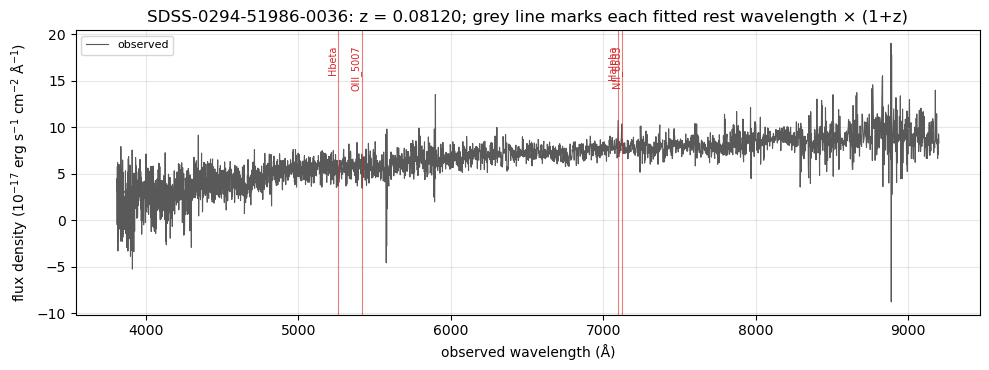

In [11]:
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(lam, coadd["flux"].astype(float), lw=.8, color="0.35", label="observed")
z = measured.redshift
for line in measured.lines:
    rest = gspec.constants.TARGET_LINES[line]
    ax.axvline(rest * (1 + z), color="C3", lw=.8, alpha=.6)
    ax.text(rest * (1 + z), ax.get_ylim()[1] * .92, line, rotation=90,
            fontsize=7, ha="right", va="top", color="C3")
ax.set_xlabel("observed wavelength (Å)"); ax.set_ylabel("flux density ($10^{-17}$ erg s$^{-1}$ cm$^{-2}$ Å$^{-1}$)")
ax.set_title(f"{measured.case_id}: z = {z:.5f}; grey line marks each fitted rest wavelength × (1+z)")
ax.legend(loc="upper left", fontsize=8); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

## 9. The provenance chain

Every published number should be traceable to bytes. The chain here has three
links, each a SHA-256:

```
archive file  --(download, verified)-->  case file  --(gspec measure)-->  CSV row
```

The fitter is deterministic — the same case produces the same CSV, byte for byte —
so the hash of the archive file is enough to reproduce the measurement.

In [12]:
# The CLI writes fetch_manifest.json for a whole run; this records this one object
# under a name of its own, so running the notebook never overwrites a batch record.
manifest_path = ROOT / "data" / "raw" / "provenance" / "notebook_run.json"
manifest_path.parent.mkdir(parents=True, exist_ok=True)
(manifest_path).write_text(json.dumps({
    "tool": "tools/download_sdss.py", "archive": D.BASE,
    "objects": [result.as_dict()], "ok": 1, "failed": 0}, indent=2) + "\n")

import hashlib
csv_path = ROOT / "data" / "raw" / "measurements.csv"
from gspec.cli import measure_directory
measure_directory(cases_dir, csv_path, verbose=False)

print("archive :", result.sha256)
print("case    :", fits_to_case.sha256_of(case_path))
print("csv     :", hashlib.sha256(csv_path.read_bytes()).hexdigest())
print("csv rows:", len(csv_path.read_text().splitlines()) - 1)

archive : 12e069c2cceb53459b49204f3f508aef3acdd704fd14a136c0b6449e8a118554
case    : 3f35ce89277a08d9280627042524cd2e486c426e7d960cb33e7b12952e2afc8e
csv     : aeaab91d9c74bdd6b501767c7773b057cf40ecae4a7e46cd7f5df08d7801576c
csv rows: 4


## 10. What this workflow cannot tell you

Four limits, stated because they bound every number above.

1. **One object is not a sample.** The pipeline measures what is in the fibre. It
   says nothing about a population, and the cases where it fails are not rare.
2. **The stellar-absorption term is phenomenological.** The model includes it and
   lets BIC decide whether to keep it, but the project has not demonstrated that it
   separates stellar from nebular light. `docs/methods.md` §4.2 says so.
3. **Uncertainties are statistical and environment-fragile.** On some spectra the
   formal errors depend on how the covariance treats bound-pinned parameters;
   `docs/limitations.md` L4 measures the effect.
4. **The flux scale is the survey's.** No aperture correction, no extinction
   correction, no absolute calibration beyond what `run2d=26` provides.

Where to read more: `docs/methods.md` for the numerics, `docs/limitations.md`
L1–L16 for the measurements behind each caveat, `docs/sdss-tutorial.md` for the
same workflow as a command-line walkthrough, and `validation/report.md` for the
validation this pipeline passed.